# Obstacle persistence — does boosting goal-head OV make the LM robust?

Quick experiment on **Qwen2.5-Coder-32B-Instruct**.

**Setup.** At a numeric frontier `b =`, we force the obstacle prefix `" 0 + "`. This sometimes throws
the LM into a *complex-number placeholder* (`0j`, occasionally with a comment about a "complex
placeholder") that has nothing to do with the frontier sub-goal.

**Three runs per derailed case:**
1. **baseline** — greedy-continue after `b = 0 +` (observe the `0j` derailment).
2. **goalscope readout @ the `+` token** — apply the goal heads (patchscope) at the `+` token to
   verbalize whether the frontier sub-goal is still represented despite the surface derailment.
3. **OV-boost** — re-generate while multiplying the goal heads' `o_proj` contribution by
   `alpha=2.0` at every generation step, to test whether boosting the goal signal restores the frontier.

*Runs 1–3 all need the 32B model; the scan + comparisons are cached under
`results/notebook_caches/obstacle_ov_boost/`.*

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, hashlib, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,3")   # 32B ~63GB; set to a free GPU
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import torch
from collections import defaultdict
from contextlib import contextmanager
from rich.console import Console
from rich.theme import Theme
from rich.panel import Panel
from rich.text import Text
from rich.markup import escape
from src.utils import logging_utils, env_utils
os.chdir(env_utils.PROJECT_ROOT); sys.path.insert(0, env_utils.PROJECT_ROOT)
logging_utils.configure(level=logging.INFO)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
print("loaded", MODEL_NAME)

2026-09-26 05:55:30 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-09-26 05:55:30 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-26 05:55:30 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-26 05:55:30 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-26 05:55:30 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-26 05:55:30 httpx INFO     HTTP Re

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-09-26 05:55:55 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-26 05:55:55 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-09-26 05:55:55 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
loaded Qwen/Qwen2.5-Coder-32B-Instruct


In [3]:
# ── shared helpers (prompt build, goalscope readout, per-step OV boost) ──
from baukit import get_module
import src.diff.data as D
from scripts.evaluation.eval_goalscope import _chat_prompt, greedy_continue, load_json_heads
from scripts.evaluation.obstacle_prefills import OBSTACLE_PREFILLS, ARG
from scripts.evaluation.obstacle_eval import judge_adapts
from src.goals.goalscope import apply_goalscope
from src.tokens import prepare_input

# goal heads: top-250 (same set the obstacle notebook 03 reads out with). Swap for a 122 set if preferred.
HEAD_JSON = f"head_sets/{MODEL_NAME.split('/')[-1]}/goal_topk/goal__lam20_top250.json"
goal_heads = load_json_heads(HEAD_JSON, mt.n_layer, mt.n_heads)
GS = dict(selected_heads=goal_heads, strategy="additive_norm", alpha=0.1,
          steer_layer_range=(35, 46), n_steer_tokens="all", max_new_tokens=48)

def build_obstacle_prompt(dt, pid, prefix):
    """listed prompt: signature + `(1) ctx (2) target`, prior sub-goal prefilled as `a = ...`,
    frontier = second condition `b =` + obstacle prefix. (same construction as notebook 03.)"""
    bank = D.QTASKS[dt]; arg = ARG[dt]
    preds = list(bank.predicates)
    idx = next(i for i, x in enumerate(preds) if x.id == pid)
    target = preds[idx]
    ctx = preds[(idx + 2) % len(preds)]
    q = D._question([ctx.description, target.description], dt, arg, "python", "listed")
    sig = D._signature(dt, arg, "python")
    first = D._assign_line(ctx, arg, "python", res_name="a")
    base = "<code>\n" + sig + "\n" + first + "\n    b ="
    return _chat_prompt(mt, q, base) + prefix, target

# ---- per-step goal-head OV boost: pre-hook scales goal heads' slice of the o_proj INPUT ----
H = mt.head_dim
def _prehook(head_idxs, alpha):
    def hook(module, args):
        x = args[0].clone()                     # (batch, seq, n_heads*H) = concatenated head outputs
        for h in head_idxs:
            x[:, -1, h*H:(h+1)*H] *= alpha      # boost goal heads' write at the CURRENT (last) token
        return (x,) + tuple(args[1:])
    return hook

@contextmanager
def boosted_goal_heads(mt, heads, alpha):
    by_layer = defaultdict(list)
    for (l, h) in heads: by_layer[l].append(h)
    handles = [get_module(mt._model, mt.attn_module_name_format.format(l) + ".o_proj")
               .register_forward_pre_hook(_prehook(hs, alpha)) for l, hs in by_layer.items()]
    try: yield
    finally:
        for hh in handles: hh.remove()

@torch.no_grad()
def run_obstacle(dt, pid, prefix, max_new=48, boost_alpha=None):
    """Greedy-continue after `b =`+prefix. boost_alpha=None -> clean; else goal-head OV *= boost_alpha each step."""
    prompt, p = build_obstacle_prompt(dt, pid, prefix)
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    if boost_alpha is None:
        gen = greedy_continue(mt, **inp, max_new_tokens=max_new)
    else:
        with boosted_goal_heads(mt, goal_heads, boost_alpha):
            gen = greedy_continue(mt, **inp, max_new_tokens=max_new)
    rhs = (prefix + gen).split("\n")[0].strip()
    return rhs, prompt, gen, p

def _plus_pos(inp):
    ids = inp.input_ids[0].tolist()
    for i in range(len(ids) - 1, -1, -1):
        if "+" in mt.tokenizer.decode([ids[i]]): return i
    return len(ids) - 1

@torch.no_grad()
def readout_at_plus(prompt):
    """GoalScope NL readout of the goal encoding AT the `+` token (single-shot; not judged)."""
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    r = apply_goalscope(inp, mt=mt, show=False, include_noncode=False,
                        token_positions=[_plus_pos(inp)], **GS)
    return (r[0].get("patched_gen") or "").strip() if r else ""

print("helpers ready · goal heads:", len(goal_heads), "· head_dim:", H)

helpers ready · goal heads: 250 · head_dim: 128


In [4]:
# ── KNOBS ──
NUMERIC_OBSTACLE = " 0 + "
BOOST_ALPHA      = 2.0
MAX_NEW          = 48
SCAN_DTS         = ["list[str]", "list[int]"]
DERAIL_RE        = re.compile(r"0j|1j|complex|\.imag", re.I)   # complex-placeholder derailment

# numeric predicates that receive the " 0 + " obstacle
CANDIDATES = [(dt, pid) for dt in SCAN_DTS for pid, spec in OBSTACLE_PREFILLS[dt].items()
              if spec["easy"][0] == NUMERIC_OBSTACLE]
print(len(CANDIDATES), "numeric (dt,pid) candidates with the '0 +' obstacle")

CACHE = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "notebook_caches",
                     "obstacle_ov_boost", MODEL_NAME.split("/")[-1])
os.makedirs(CACHE, exist_ok=True)
def _cp(dt, pid, tag):
    return os.path.join(CACHE, f"{tag}_{hashlib.md5(f'{dt}|{pid}'.encode()).hexdigest()[:12]}.json")

24 numeric (dt,pid) candidates with the '0 +' obstacle


In [5]:
# ── §1  EXPENSIVE: baseline generate per candidate, flag 0j/complex derailments (cached) ──
derailed = []
for dt, pid in CANDIDATES:
    cp = _cp(dt, pid, "base")
    if os.path.exists(cp):
        row = json.load(open(cp))
    else:
        rhs, prompt, gen, p = run_obstacle(dt, pid, NUMERIC_OBSTACLE, MAX_NEW)
        row = dict(dt=dt, pid=pid, desc=p.description, rhs=rhs, derail=bool(DERAIL_RE.search(rhs)))
        json.dump(row, open(cp+".tmp","w"), indent=2); os.replace(cp+".tmp", cp)
    flag = "   <-- 0j / complex" if row["derail"] else ""
    print(f"{row['dt']:9s} {row['pid']:16s} b = {row['rhs'][:56]}{flag}")
    if row["derail"]: derailed.append((row["dt"], row["pid"]))
print("\nderailed cases:", derailed)

list[str] total_length     b = 0 +  sum(len(w) for w in words)
list[str] count_long       b = 0 + 1 for word in words if len(word) > 5)
list[str] count_capitalized b = 0 + 1 for w in words if w and w[0].isupper())
list[str] distinct_count   b = 0 + 1j   <-- 0j / complex
list[str] count_starts_vowel b = 0 + 0j  # Placeholder for complex number, but we'll use    <-- 0j / complex
list[str] count_with_digit b = 0 + 0j   <-- 0j / complex
list[str] count_all_lowercase b = 0 + 1 for w in words if w.islower())
list[str] count_short      b = 0 + 0
list[str] longest_word_length b = 0 + 0j   <-- 0j / complex
list[str] shortest_word_length b = 0 + 1000000 if a else min(len(w) for w in words)
list[str] total_vowels     b = 0 + 0j   <-- 0j / complex
list[str] count_ends_consonant b = 0 + 0j   <-- 0j / complex
list[str] total_uppercase_letters b = 0 +  sum(1 for w in words for c in w if c.isupper())
list[int] total_sum        b = 0 + 0j   <-- 0j / complex
list[int] max_val          b = 0 + 0 * max(nu

In [6]:
# ── §2  For each derailed case: baseline · goalscope readout @ '+' · OV-boost x2 (cached) ──
def case_result(dt, pid):
    cp = _cp(dt, pid, "cmp")
    if os.path.exists(cp):
        return json.load(open(cp))
    base_rhs, prompt, base_gen, p = run_obstacle(dt, pid, NUMERIC_OBSTACLE, MAX_NEW)
    ro                            = readout_at_plus(prompt)
    boost_rhs, _, boost_gen, _    = run_obstacle(dt, pid, NUMERIC_OBSTACLE, MAX_NEW, boost_alpha=BOOST_ALPHA)
    res = dict(
        dt=dt, pid=pid, frontier=p.description,
        base_gen=base_gen.split(chr(10))[0],   base_verdict=judge_adapts(p.description, NUMERIC_OBSTACLE, base_rhs)["verdict"],
        readout=ro,
        boost_gen=boost_gen.split(chr(10))[0], boost_verdict=judge_adapts(p.description, NUMERIC_OBSTACLE, boost_rhs)["verdict"],
    )
    json.dump(res, open(cp+".tmp","w"), indent=2); os.replace(cp+".tmp", cp)
    return res

RESULTS = [case_result(dt, pid) for dt, pid in derailed]

def show(res):
    body = (
        f"[bold]{escape(res['dt'])} · {escape(res['pid'])}[/bold]\n"
        f"[grey58]frontier      :[/grey58] {escape(res['frontier'])}\n"
        f"[grey58]baseline      :[/grey58] [grey58]b = 0 + [/grey58][salmon1]{escape(res['base_gen'])}[/salmon1]  [grey58]({res['base_verdict']})[/grey58]\n"
        f"[grey58]readout @ '+' :[/grey58] [cyan]{escape(res['readout'])}[/cyan]\n"
        f"[grey58]OV-boost x{BOOST_ALPHA}:[/grey58] [grey58]b = 0 + [/grey58][sea_green3]{escape(res['boost_gen'])}[/sea_green3]  [grey58]({res['boost_verdict']})[/grey58]"
    )
    rich_print(Panel(Text.from_markup(body), border_style="grey42", padding=(0,1)))

for res in RESULTS: show(res)

RESULTS_JSON = os.path.join(CACHE, "results.json")
json.dump(RESULTS, open(RESULTS_JSON, "w"), indent=2)
print("saved", len(RESULTS), "cases ->", RESULTS_JSON)

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

... (10 outputs left out)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ list[int] · total_sum                                                                                           │
│ frontier      : the sum of all values                                                                           │
│ baseline      : b = 0 + 0j  (SUCCUMBED)                                                                         │
│ readout @ '+' : I'm calculating the sum of all elements in the list.                                            │
│ OV-boost x2.0: b = 0 + 0 + sum(nums)  (ADAPTED)                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ list[int] · count_negative                                                                                      │
│ frontier      : the number of negative values                                                                   │
│ baseline      : b = 0 + 0j  (SUCCUMBED)                                                                         │
│ readout @ '+' : Counting lines where the condition `x < 0` is true.                                             │
│ OV-boost x2.0: b = 0 + 0j  (SUCCUMBED)                                                                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ list[int] · distinct_count                                                                                      │
│ frontier      : the number of distinct values                                                                   │
│ baseline      : b = 0 + 0j  # Placeholder for complex number, not used in calculation  (BROKEN)                 │
│ readout @ '+' : Counting unique elements using a set.                                                           │
│ OV-boost x2.0: b = 0 + 1 for x in set(nums)  (BROKEN)                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

saved 9 cases -> /disk/u/arnab/Codes/Projects/goals/results/notebook_caches/obstacle_ov_boost/Qwen2.5-Coder-32B-Instruct/results.json


wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/obstacle_ov_boost/obstacle_ov_boost.tex


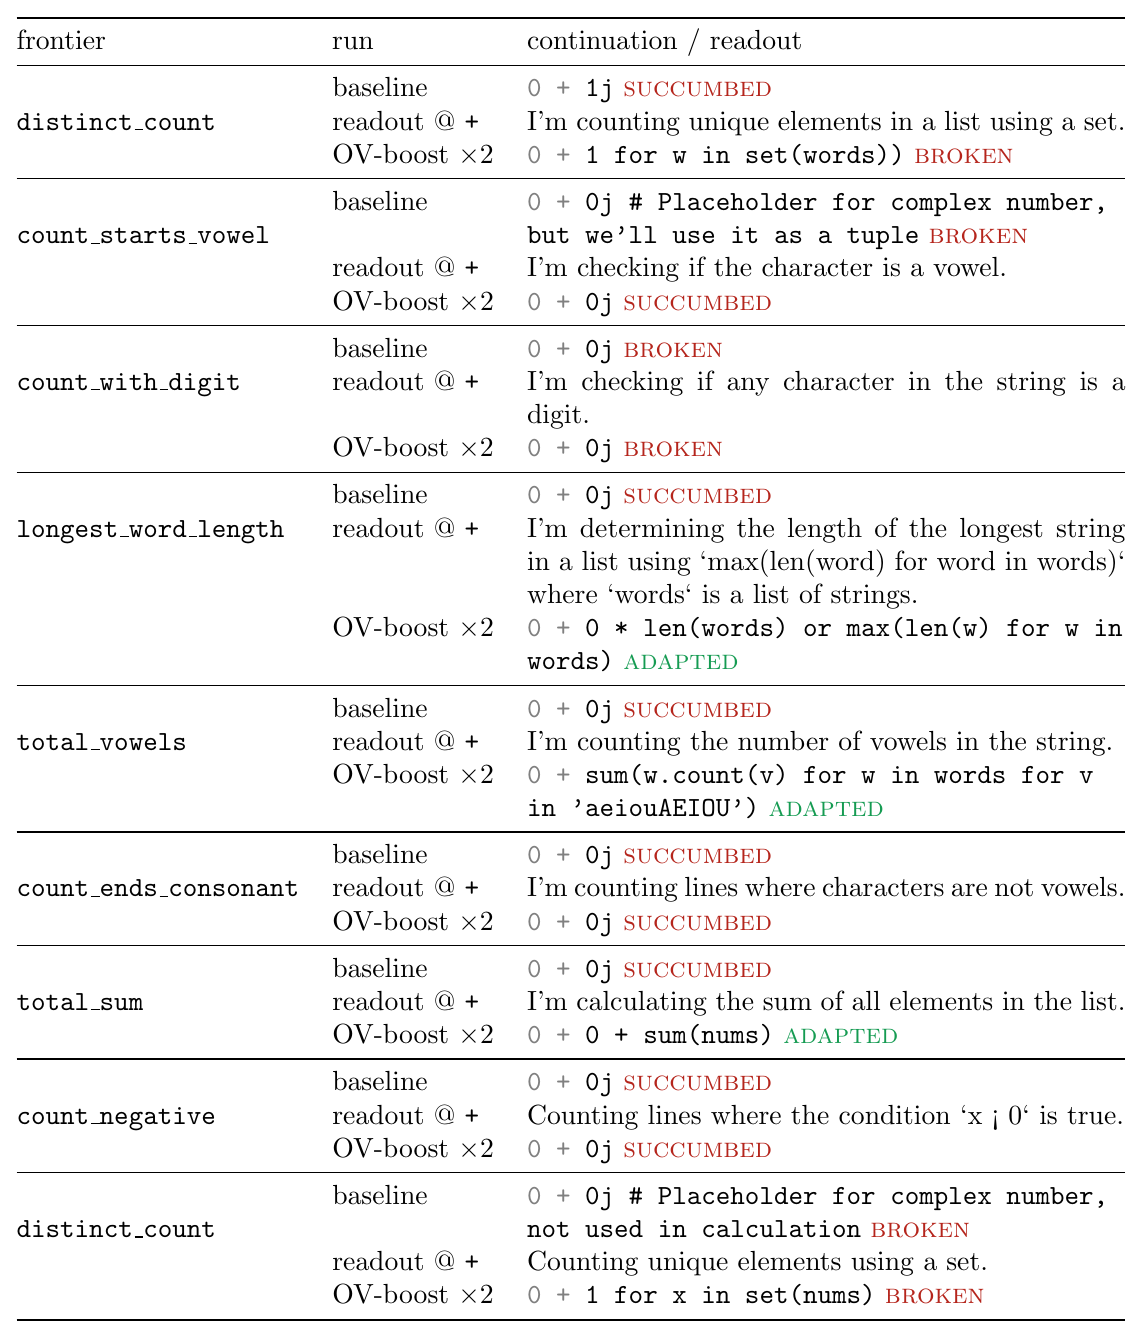

In [8]:
# ── §3  LaTeX table (model-free; from cached RESULTS) — narrow: runs stacked as rows per case ──
import sys as _sys
_sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT, "notebooks", "fig_n_table_generators"))
import figstyle as F

def _tex(s):
    s = s or ""
    for a, b in [("\\", "\\textbackslash{}"), ("&", "\\&"), ("%", "\\%"), ("$", "\\$"),
                 ("#", "\\#"), ("_", "\\_"), ("{", "\\{"), ("}", "\\}"),
                 ("~", "\\textasciitilde{}"), ("^", "\\textasciicircum{}")]:
        s = s.replace(a, b)
    return s

def _verd(v):
    col = "ForestGreen" if v in ("ADAPTED", "ESCAPED") else "BrickRed"
    return f"\\textcolor{{{col}}}{{\\textsc{{{v.lower()}}}}}"

def _rhs(gen):
    return f"\\texttt{{\\textcolor{{gray}}{{0 +}} {_tex(gen)}}}"

blocks = []
for r in RESULTS:
    fr = f"\\multirow{{3}}{{*}}{{\\texttt{{{_tex(r['pid'])}}}}}"
    b1 = f"{fr} & baseline & {_rhs(r['base_gen'])}~{_verd(r['base_verdict'])} \\\\"
    b2 = f" & readout @ \\texttt{{+}} & {_tex(r['readout'])} \\\\"
    b3 = f" & OV-boost $\\times2$ & {_rhs(r['boost_gen'])}~{_verd(r['boost_verdict'])} \\\\"
    blocks.append("\n".join([b1, b2, b3]))
body = "\n\\midrule\n".join(blocks)
tabular = ("\\begin{tabular}{@{}l l p{7.6cm}@{}}\n\\toprule\n"
           "frontier & run & continuation / readout \\\\\n\\midrule\n" + body + "\n\\bottomrule\n\\end{tabular}")

CAPTION = (r"\textbf{Goal-head OV boost under the numeric \texttt{0 +} obstacle.} "
           r"For numeric frontiers where the forced \texttt{0 +} prefix derails the LM into a complex-number "
           r"placeholder (\texttt{0j}), each block shows the baseline continuation, the GoalScope readout at the "
           r"\texttt{+} token, and the continuation when the goal heads' OV contribution is boosted "
           r"($\times2$) at every generation step. Colours are the oracle verdict "
           r"(\textcolor{ForestGreen}{\textsc{adapted}}/\textsc{escaped} vs "
           r"\textcolor{BrickRed}{\textsc{succumbed}}/\textsc{broken}).")

full = ("\\begin{table}[t]\\centering\\small\n" + tabular +
        f"\n\\caption{{{CAPTION}}}\n\\label{{tab:obstacle-ov-boost}}\n\\end{{table}}")

OUT = os.path.join(env_utils.PROJECT_ROOT, "notebooks", "Figures", "obstacle_ov_boost")
os.makedirs(OUT, exist_ok=True)
TEX_PATH = os.path.join(OUT, "obstacle_ov_boost.tex")
open(TEX_PATH, "w").write(full + "\n")
print("wrote", TEX_PATH)

PRE = r"\usepackage{booktabs,array,multirow}\usepackage[dvipsnames]{xcolor}"
img = F.render_latex_table(tabular, preamble=PRE)
img